<a href="https://colab.research.google.com/github/swiechj/deep-learning-lab/blob/ResNET-56/ResNET_56.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Residual Learning: Implementacja, Trening i Reprodukcja Eksperymentów ResNet-56 na zbiorze CIFAR-10

**Podstawa teoretyczna:** Kaiming He, Xiangyu Zhang, Shaoqing Ren, Jian Sun, *"Deep Residual Learning for Image Recognition"*, Microsoft Research (arXiv:1512.03385v1, 2015).

---

### Spis treści projektu
1. **Wstęp teoretyczny i cel projektu** — problem degradacji sieci głębokich, mechanizm uczenia rezydualnego i specyfikacja architektury ResNet-56 dla CIFAR-10.
2. **Konfiguracja środowiska (T4) i analiza wstępna danych (EDA)** — sprawdzenie zasobów GPU, eksploracja CIFAR-10, obliczenie średniej pikselowej (*per-pixel mean*) oraz wizualizacja augmentacji.
3. **Implementacja architektury (ResNet-56 i PlainNet-56)** — implementacja bloków rezydualnych, inicjalizacja wag He (Kaiming) oraz weryfikacja liczby parametrów względem artykułu.
4. **Potok treningowy (AMP/FP16) i trening bazowy ResNet-56** — implementacja treningu, ewaluacja, macierz pomyłek i analiza błędów.
5. **Odtworzenie kluczowych eksperymentów z artykułu**:
   - *Eksperyment 5.1:* Zjawisko degradacji — **Plain-20 vs Plain-56** oraz **ResNet-20 vs ResNet-56**.
   - *Eksperyment 5.2:* Analiza odchyleń standardowych odpowiedzi warstw.
   - *Eksperyment 5.3:* Wpływ rodzaju połączenia skrótowego.
6. **Fine-tuning hiperparametrów i współczesne usprawnienia** — kontrolowana optymalizacja na podziale walidacyjnym 45k/5k (Cosine Annealing + Warmup, Weight Decay, Label Smoothing, Cutout/RandomErasing) oraz finalna ewaluacja na zbiorze testowym.
7. **Wnioski i podsumowanie** — synteza uzyskanych rezultatów w odniesieniu do oryginalnej publikacji.

## 1. Wstęp teoretyczny i cel projektu

### 1.1. Problem degradacji sieci głębokich (*Degradation Problem*)
Przed publikacją pracy He et al. (2015) powszechnie uważano, że główną przeszkodą w trenowaniu bardzo głębokich sieci konwolucyjnych jest problem zanikających lub eksplodujących gradientów. Zastosowanie odpowiedniej inicjalizacji wag (np. inicjalizacja He) oraz warstw **Batch Normalization (BN)** rozwiązało jednak problem samej zbieżności gradientów, ujawniając inne, nieintuicyjne zjawisko — **problem degradacji**:
* Wraz ze zwiększaniem głębokości klasycznej sieci (*plain network*), jej skuteczność ulega nasyceniu, a następnie gwałtownie spada.
* Co kluczowe, **nie jest to przeuczenie (*overfitting*)** — głębsza sieć osiąga **wyższy błąd również na zbiorze treningowym**.
* Teoretycznie istnieje rozwiązanie konstrukcyjne, w którym dodane warstwy pełnią rolę odwzorowania tożsamościowego (*identity mapping*), więc głębsza sieć nie powinna mieć wyższego błędu treningowego niż płytsza. Fakt, że optymalizator SGD nie potrafi go znaleźć, dowodzi fundamentalnych trudności w optymalizacji głębokich stosów nieliniowych warstw.

### 1.2. Idea uczenia rezydualnego (*Residual Learning*)
Zamiast oczekiwać, że kilka kolejnych warstw bezpośrednio dopasuje pożądane odwzorowanie $\mathcal{H}(x)$, autorzy przeformułowali zadanie tak, aby warstwy uczyły się funkcji **rezydualnej**:
$$\mathcal{F}(x) := \mathcal{H}(x) - x$$
Wówczas oryginalne odwzorowanie przyjmuje postać:
$$y = \mathcal{F}(x, \{W_i\}) + x$$
Operacja dodawania realizowana jest przez **połączenie skrótowe (*shortcut / skip connection*)** o charakterze odwzorowania tożsamościowego, które nie wprowadza dodatkowych parametrów ani narzutu obliczeniowego. Jeśli optymalne odwzorowanie jest bliskie tożsamościowemu, znacznie łatwiej jest wyzerować wagi gałęzi rezydualnej ($\mathcal{F}(x) \to 0$) niż nauczyć się funkcji identycznościowej za pomocą stosu warstw z aktywacją ReLU.

### 1.3. Architektura ResNet dla CIFAR-10
W przeciwieństwie do wersji dla ImageNet (wejście $224\times 224$, wstępna konwolucja $7\times 7$ i MaxPooling), architektura dla CIFAR-10 ($32\times 32$) jest lekka i ma postać $6n + 2$ warstw z wagami:

| Etap | Rozmiar mapy cech | Liczba warstw | Liczba filtrów | Redukcja wymiaru (stride=2) |
| :--- | :---: | :---: | :---: | :---: |
| `conv1` | $32 \times 32$ | $1$ | $16$ | Nie |
| `stage1` | $32 \times 32$ | $2n$ ($n$ bloków) | $16$ | Nie |
| `stage2` | $16 \times 16$ | $2n$ ($n$ bloków) | $32$ | Pierwszy blok (`stride=2`) |
| `stage3` | $8 \times 8$ | $2n$ ($n$ bloków) | $64$ | Pierwszy blok (`stride=2`) |
| `head` | $1 \times 1$ | Global Avg Pool + FC(10) | $10$ | — |

Dla **ResNet-56** przyjmujemy **$n = 9$** ($6 \times 9 + 2 = 56$ warstw z wagami, 27 połączeń skrótowych, ok. **0.85M parametrów**). W oryginalnej publikacji (Tabela 6) ResNet-56 osiągnął błąd klasyfikacji na zbiorze testowym CIFAR-10 równy **6.97%** (dokładność **93.03%**).

## 2. Konfiguracja środowiska (T4) i analiza wstępna danych (EDA)

### 2.1. Inicjalizacja środowiska, kontrola GPU i ustawienia powtarzalności
Poniższa komórka konfiguruje biblioteki, weryfikuje obecność karty graficznej NVIDIA T4 oraz definiuje globalną konfigurację projektu.

> **Tryb pracy (`FAST_MODE`):**
> * `FAST_MODE = False` *(zalecane dla pełnej reprodukcji)*: 64 000 iteracji (~164 epoki dla 50k obrazów przy `batch_size=128`), spadek LR w 32k i 48k iteracji. Czas treningu 1 modelu ResNet-56 na T4 to ok. 4–6 minut.
> * `FAST_MODE = True` *(tryb szybki / demonstracyjny)*: 60 epok ze skalowanymi progami LR — pozwala przejść przez cały notebook (wszystkie modele i fine-tuning) w ok. 8–10 minut.

In [8]:
import os
import gc
import time
import copy
import json
import math
import random
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, Dataset
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import confusion_matrix, classification_report

# Styl wykresów
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# --- KONFIGURACJA GLOBALNA ---
SEED = 42
FAST_MODE = False
USE_AMP = True
BATCH_SIZE = 128
NUM_WORKERS = 2

CHECKPOINT_DIR = Path("./checkpoints_resnet56")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.deterministic = False


def cleanup_gpu() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


seed_everything(SEED)

# Sprawdzenie sprzętu
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version : {torch.__version__}")
print(f"Torchvision ver : {torchvision.__version__}")
print(f"Device          : {device}")

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU Model       : {gpu_name}")
    print(f"Total VRAM      : {vram_gb:.2f} GB")
    if "T4" not in gpu_name:
        print("Uwaga: Wykryto inne GPU niż T4")
else:
    USE_AMP = False
    print("OSTRZEŻENIE: Brak GPU! Włącz T4 GPU w Google Colab (Środowisko wykonawcze -> Zmień typ).")


if FAST_MODE:
    PAPER_MAX_ITERS = 23_400     # ~60 epok
    PAPER_MILESTONES = [11_700, 17_550]  # 50% i 75% iteracji
    FT_EPOCHS = 50
    print("\n[TRYB FAST_MODE=True] Skrócony trening demonstracyjny (ok. 60 epok).")
else:
    PAPER_MAX_ITERS = 64_000
    PAPER_MILESTONES = [32_000, 48_000]
    FT_EPOCHS = 164
    print("\n[TRYB PEŁNEJ REPRODUKCJI] 64 000 iteracji (milestones: 32k, 48k)")

PyTorch version : 2.14.1+cu130
Torchvision ver : 0.29.1+cu130
Device          : cuda
GPU Model       : Tesla T4
Total VRAM      : 14.56 GB

[TRYB PEŁNEJ REPRODUKCJI] 64 000 iteracji (milestones: 32k, 48k)


### 2.2. Analiza wstępna zbioru CIFAR-10 (EDA)
Zbiór **CIFAR-10** składa się z **60 000 kolorowych obrazów** w rozdzielczości $32 \times 32$ piksele (RGB), podzielonych na **10 klas** (50 000 obrazów treningowych i 10 000 testowych).

W poniższej analizie sprawdzono:
1. Zbalansowanie klas w zbiorze treningowym i testowym.
2. Podstawowe statystyki kanałów RGB (średnia, odchylenie standardowe).
3. **Średni obraz pikselowy (*per-pixel mean*)** o wymiarach $32 \times 32.
4. Przykładowe próbki z każdej klasy, aby ocenić trudność wizualną zadania (niska rozdzielczość, zmienność tła i skali obiektów).

Liczba obrazów treningowych : 50,000
Liczba obrazów testowych    : 10,000
Kształt pojedynczego obrazu : (32, 32, 3) (dtype=uint8)
Klasy (10)                 : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Rozkład klas:


,Klasa,Train,Test
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000



Średnia kanałowa (R, G, B)  : [0.4914 0.4822 0.4465]
Odchylenie std (R, G, B)    : [0.247  0.2435 0.2616]
Zakres per-pixel mean       : [0.3921, 0.5501]


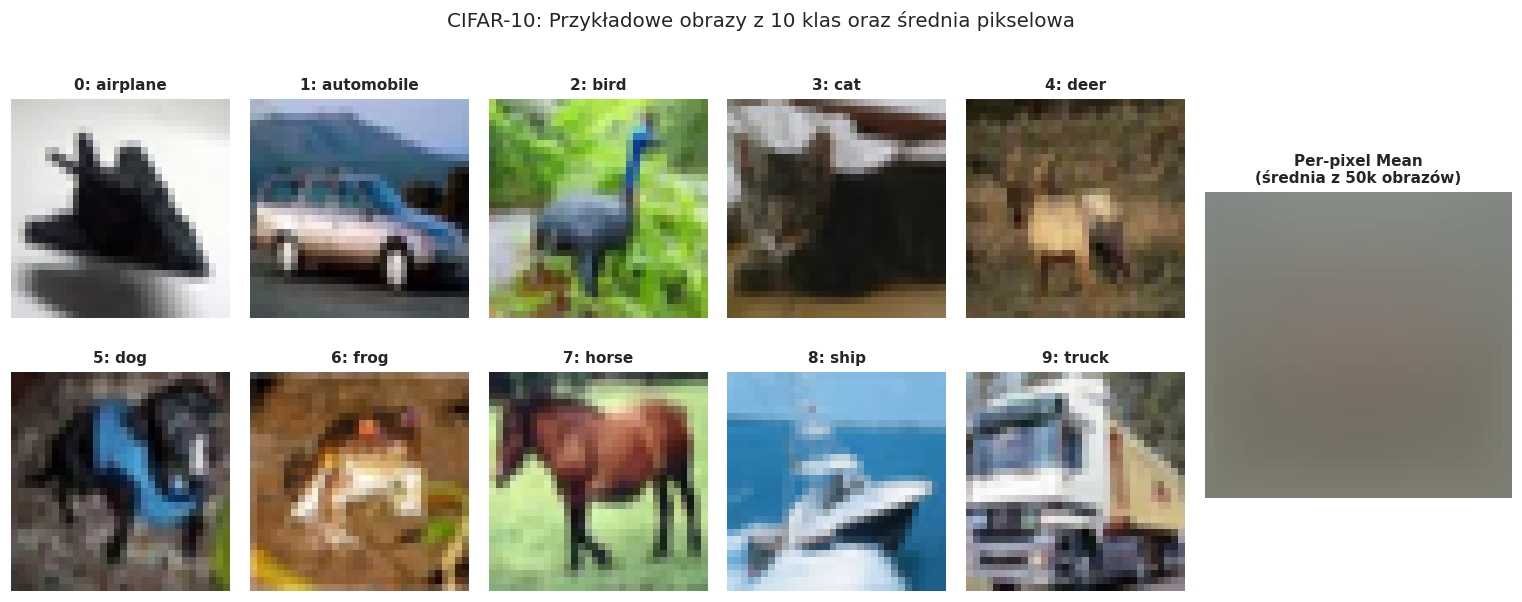

In [9]:
DATA_DIR = Path("./data")

raw_train = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
raw_test = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

CLASSES = raw_train.classes
print(f"Liczba obrazów treningowych : {len(raw_train):,}")
print(f"Liczba obrazów testowych    : {len(raw_test):,}")
print(f"Kształt pojedynczego obrazu : {raw_train.data[0].shape} (dtype={raw_train.data.dtype})")
print(f"Klasy ({len(CLASSES)})                 : {CLASSES}")

# 1. Analiza rozkładu klas
train_counts = pd.Series(raw_train.targets).value_counts().sort_index()
test_counts = pd.Series(raw_test.targets).value_counts().sort_index()
dist_df = pd.DataFrame({
    "Klasa": CLASSES,
    "Train": train_counts.values,
    "Test": test_counts.values
})
print("\nRozkład klas:")
display(dist_df)

# 2. Statystyki kanałów RGB oraz średnia pikselowa
train_float = raw_train.data.astype(np.float32) / 255.0  # (50000, 32, 32, 3)
channel_mean = train_float.mean(axis=(0, 1, 2))
channel_std = train_float.std(axis=(0, 1, 2))
per_pixel_mean_full = train_float.mean(axis=0)          # (32, 32, 3)

print(f"\nŚrednia kanałowa (R, G, B)  : {np.round(channel_mean, 4)}")
print(f"Odchylenie std (R, G, B)    : {np.round(channel_std, 4)}")
print(f"Zakres per-pixel mean       : [{per_pixel_mean_full.min():.4f}, {per_pixel_mean_full.max():.4f}]")

# 3. Wizualizacja: przykładowe obrazy z każdej klasy + obraz średniej pikselowej
fig = plt.figure(figsize=(14, 5.5))
gs = fig.add_gridspec(2, 6, width_ratios=[1, 1, 1, 1, 1, 1.4])

for cls_idx, cls_name in enumerate(CLASSES):
    row = cls_idx // 5
    col = cls_idx % 5
    ax = fig.add_subplot(gs[row, col])
    idx = np.where(np.array(raw_train.targets) == cls_idx)[0][0]
    ax.imshow(raw_train.data[idx])
    ax.set_title(f"{cls_idx}: {cls_name}", fontsize=10, fontweight="bold")
    ax.axis("off")

ax_mean = fig.add_subplot(gs[:, 5])
ax_mean.imshow(np.clip(per_pixel_mean_full, 0, 1))
ax_mean.set_title("Per-pixel Mean\n(średnia z 50k obrazów)", fontsize=10, fontweight="bold")
ax_mean.axis("off")

plt.suptitle("CIFAR-10: Przykładowe obrazy z 10 klas oraz średnia pikselowa", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

Batchy na epokę (50k train): 391 | (10k test): 79


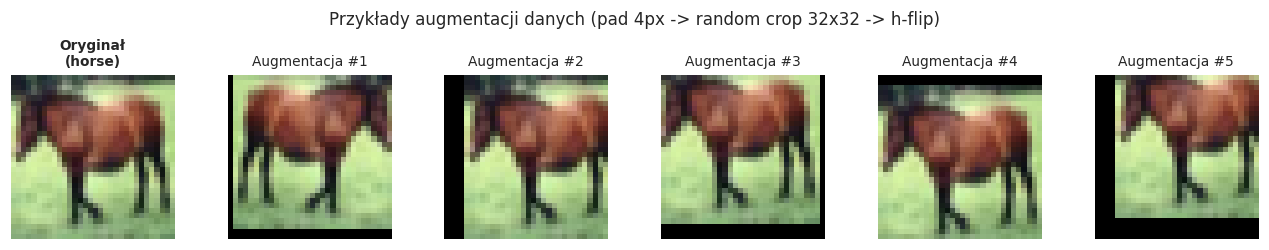

In [10]:

class PerPixelMeanSubtract:
    """Odejmuje średnią pikselową (3, 32, 32) i opcjonalnie skaluje przez std kanałowe."""
    def __init__(self, per_pixel_mean_hwc: np.ndarray, channel_std: np.ndarray = None):
        self.mean = torch.from_numpy(per_pixel_mean_hwc.transpose(2, 0, 1)).float()
        if channel_std is not None:
            self.std = torch.from_numpy(channel_std).float().view(3, 1, 1)
        else:
            self.std = None

    def __call__(self, tensor: torch.Tensor) -> torch.Tensor:
        out = tensor - self.mean
        if self.std is not None:
            out = out / self.std
        return out


class TransformedSubset(Dataset):
    """Wrapper pozwalający na różne transformacje dla train i val z tego samego zbioru bazowego."""
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, target = self.base_dataset[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, target


def build_transforms(per_pixel_mean_hwc: np.ndarray, channel_std: np.ndarray, use_cutout: bool = False):
    """
    Buduje potok transformacji:
    1. Konwersja do tensora [0, 1]
    2. Odjęcie średniej pikselowej (z normalizacją wariancji -> średnia każdego piksela = 0.0)
    3. Padding 4 px zerami (co po wycentrowaniu odpowiada wartości średniej) + RandomCrop(32)
    4. RandomHorizontalFlip(p=0.5)
    5. Opcjonalnie RandomErasing (Cutout) dla eksperymentów fine-tuningu
    """
    train_ops = [
        transforms.ToTensor(),
        PerPixelMeanSubtract(per_pixel_mean_hwc, channel_std),
        transforms.RandomCrop(32, padding=4, fill=0.0),
        transforms.RandomHorizontalFlip(p=0.5),
    ]
    if use_cutout:
        train_ops.append(
            transforms.RandomErasing(p=0.5, scale=(0.06, 0.25), ratio=(0.8, 1.25), value=0.0)
        )

    test_ops = [
        transforms.ToTensor(),
        PerPixelMeanSubtract(per_pixel_mean_hwc, channel_std),
    ]
    return transforms.Compose(train_ops), transforms.Compose(test_ops)


def get_cifar10_loaders(
    batch_size: int = BATCH_SIZE,
    val_split: bool = False,
    use_cutout: bool = False,
    seed: int = SEED
):
    """
    Zwraca DataLoadery dla CIFAR-10:
    - val_split=False: 50k train / 10k test
    - val_split=True : 45k train / 5k val
    """
    base_train = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=False)
    base_test = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=False)

    loader_kwargs = dict(
        batch_size=batch_size,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        persistent_workers=(NUM_WORKERS > 0),
    )

    if not val_split:
        train_float_arr = base_train.data.astype(np.float32) / 255.0
        ppm = train_float_arr.mean(axis=0)
        c_std = train_float_arr.std(axis=(0, 1, 2))
        train_tf, test_tf = build_transforms(ppm, c_std, use_cutout=use_cutout)

        train_ds = TransformedSubset(base_train, list(range(len(base_train))), transform=train_tf)
        test_ds = TransformedSubset(base_test, list(range(len(base_test))), transform=test_tf)

        train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
        test_loader = DataLoader(test_ds, shuffle=False, **loader_kwargs)
        return train_loader, test_loader
    else:
        # Stratyfikowany podział 45k / 5k
        rng = np.random.default_rng(seed)
        targets = np.array(base_train.targets)
        train_idx, val_idx = [], []
        for c in range(10):
            c_idx = np.where(targets == c)[0]
            rng.shuffle(c_idx)
            val_idx.extend(c_idx[:500].tolist())
            train_idx.extend(c_idx[500:].tolist())

        # Średnia pikselowa wyliczana wyłącznie na 45k
        train_sub_arr = base_train.data[train_idx].astype(np.float32) / 255.0
        ppm = train_sub_arr.mean(axis=0)
        c_std = train_sub_arr.std(axis=(0, 1, 2))
        train_tf, val_tf = build_transforms(ppm, c_std, use_cutout=use_cutout)

        train_ds = TransformedSubset(base_train, train_idx, transform=train_tf)
        val_ds = TransformedSubset(base_train, val_idx, transform=val_tf)

        train_loader = DataLoader(train_ds, shuffle=True, **loader_kwargs)
        val_loader = DataLoader(val_ds, shuffle=False, **loader_kwargs)
        return train_loader, val_loader


# Główne DataLoadery (50k train / 10k test)
train_loader_full, test_loader = get_cifar10_loaders(batch_size=BATCH_SIZE, val_split=False)
print(f"Batchy na epokę (50k train): {len(train_loader_full)} | (10k test): {len(test_loader)}")

# Wizualizacja działania augmentacji (4px padding + random crop + horizontal flip)
sample_pil, sample_label = raw_train[7]  # przykładowy obraz
aug_vis_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
])

fig, axes = plt.subplots(1, 6, figsize=(12, 2.3))
axes[0].imshow(sample_pil)
axes[0].set_title(f"Oryginał\n({CLASSES[sample_label]})", fontsize=9, fontweight="bold")
axes[0].axis("off")
for i in range(1, 6):
    axes[i].imshow(aug_vis_tf(sample_pil))
    axes[i].set_title(f"Augmentacja #{i}", fontsize=9)
    axes[i].axis("off")
plt.suptitle("Przykłady augmentacji danych (pad 4px -> random crop 32x32 -> h-flip)", fontsize=11)
plt.tight_layout()
plt.show()

## 3. Implementacja architektury ResNet-56 oraz PlainNet-56

Kluczowe założenia implementacyjne z artykułu:
1. **Struktura bloku podstawowego (`BasicBlock`)**:
   `Conv3x3 (bez biasu) -> BatchNorm -> ReLU -> Conv3x3 (bez biasu) -> BatchNorm -> (+ shortcut) -> ReLU`.
2. **Obsługa wzrostu liczby kanałów (zmiana wymiaru $32\to 16\to 8$ oraz $16\to 32\to 64$)**:
   * **Opcja A**: połączenie tożsamościowe z podpróbkowaniem (`::2`) oraz dopełnieniem dodatkowych kanałów zerami (*zero-padding*). **Nie wprowadza żadnych dodatkowych parametrów**, dzięki czemu `ResNet-56` i `Plain-56` mają dokładnie identyczną liczbę wag (~0.85M), głębokość i szerokość.
   * **Opcja B**: liniowa projekcja $W_s x$ za pomocą konwolucji $1\times 1$ ze `stride=2` i warstwą `BatchNorm2d`.
3. **Brak warstwy Dropout**: zgodnie z artykułem autorzy rezygnują z Dropoutu na rzecz regularyzacji wynikającej z Batch Normalization oraz wąskiej architektury sieci.
4. **Inicjalizacja wag wg He et al.**: `kaiming_normal_` dla warstw konwolucyjnych i liniowych.

In [11]:
class LambdaLayer(nn.Module):
    def __init__(self, lambd):
        super().__init__()
        self.lambd = lambd

    def forward(self, x):
        return self.lambd(x)


class BasicBlock(nn.Module):
    """
    Podstawowy blok dwuwarstwowy (dwie konwolucje 3x3) dla CIFAR-10 ResNet / PlainNet.
    Obsługuje:
    - use_shortcut=True  -> blok rezydualny (ResNet)
    - use_shortcut=False -> blok klasyczny bez połączenia skrótowego (PlainNet)
    - option='A'         -> zero-padding identity shortcut (0 dodatkowych parametrów)
    - option='B'         -> 1x1 convolution projection shortcut
    """
    expansion = 1

    def __init__(
        self,
        in_planes: int,
        planes: int,
        stride: int = 1,
        use_shortcut: bool = True,
        option: str = "A",
    ):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.conv1 = nn.Conv2d(
            in_planes, planes, kernel_size=3, stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(planes)
        self.conv2 = nn.Conv2d(
            planes, planes, kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(planes)

        self.shortcut = nn.Sequential()
        if self.use_shortcut and (stride != 1 or in_planes != planes):
            if option == "A":
                # Opcja A: subsampling przestrzenny (::2) i dopełnienie kanałów zerami po obu stronach
                pad_channels = (planes - in_planes) // 2
                self.shortcut = LambdaLayer(
                    lambda x: F.pad(
                        x[:, :, ::2, ::2],
                        (0, 0, 0, 0, pad_channels, planes - in_planes - pad_channels),
                        mode="constant",
                        value=0.0,
                    )
                )
            elif option == "B":
                # Opcja B: projekcja liniowa 1x1 ze stride=2 + BN
                self.shortcut = nn.Sequential(
                    nn.Conv2d(in_planes, planes, kernel_size=1, stride=stride, bias=False),
                    nn.BatchNorm2d(planes),
                )
            else:
                raise ValueError(f"Nieznana opcja shortcut: {option}. Wybierz 'A' lub 'B'.")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        if self.use_shortcut:
            out = out + self.shortcut(x)
        out = F.relu(out, inplace=True)
        return out


class CifarResNet(nn.Module):
    """
    Architektura CIFAR-10 ResNet / PlainNet o głębokości 6n + 2 warstw z wagami.
    n=3 -> 20 warstw | n=5 -> 32 | n=7 -> 44 | n=9 -> 56 | n=18 -> 110.
    """
    def __init__(
        self,
        num_blocks_per_stage: int = 9,
        num_classes: int = 10,
        use_shortcut: bool = True,
        option: str = "A",
    ):
        super().__init__()
        self.in_planes = 16
        self.n = num_blocks_per_stage
        self.depth = 6 * num_blocks_per_stage + 2
        self.use_shortcut = use_shortcut
        self.option = option

        # Pierwsza warstwa: 3x3 conv, 16 filtrów (mapa cech 32x32)
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(16)

        # Trzy etapy po n bloków (po 2n warstw 3x3 w każdym etapie)
        self.layer1 = self._make_layer(16, num_blocks_per_stage, stride=1, use_shortcut=use_shortcut, option=option)
        self.layer2 = self._make_layer(32, num_blocks_per_stage, stride=2, use_shortcut=use_shortcut, option=option)
        self.layer3 = self._make_layer(64, num_blocks_per_stage, stride=2, use_shortcut=use_shortcut, option=option)

        # Global Average Pooling + 10-wyjściowa warstwa liniowa
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(64, num_classes)

        self._init_weights()

    def _make_layer(self, planes: int, num_blocks: int, stride: int, use_shortcut: bool, option: str):
        strides = [stride] + [1] * (num_blocks - 1)
        layers = []
        for s in strides:
            layers.append(
                BasicBlock(self.in_planes, planes, stride=s, use_shortcut=use_shortcut, option=option)
            )
            self.in_planes = planes
        return nn.Sequential(*layers)

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.layer1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = self.avgpool(out)
        out = torch.flatten(out, 1)
        out = self.fc(out)
        return out

def resnet20(option: str = "A") -> CifarResNet:
    return CifarResNet(num_blocks_per_stage=3, use_shortcut=True, option=option)

def resnet56(option: str = "A") -> CifarResNet:
    return CifarResNet(num_blocks_per_stage=9, use_shortcut=True, option=option)

def plain20() -> CifarResNet:
    return CifarResNet(num_blocks_per_stage=3, use_shortcut=False, option="A")

def plain56() -> CifarResNet:
    return CifarResNet(num_blocks_per_stage=9, use_shortcut=False, option="A")

def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Zdefiniowano klasy BasicBlock oraz CifarResNet.")

Zdefiniowano klasy BasicBlock oraz CifarResNet.


In [12]:
# Weryfikacja architektury, liczby parametrów i zgodności z Tabelą 6 artykułu
models_check = [
    ("Plain-20",             plain20(),            "0.27M"),
    ("ResNet-20 (Option A)", resnet20("A"),        "0.27M"),
    ("Plain-56",             plain56(),            "0.85M"),
    ("ResNet-56 (Option A)", resnet56("A"),        "0.85M"),
    ("ResNet-56 (Option B)", resnet56("B"),        "~0.86M (proj. 1x1)"),
]

rows = []
dummy_x = torch.randn(4, 3, 32, 32)
for name, m, paper_ref in models_check:
    n_params = count_parameters(m)
    out = m(dummy_x)
    assert out.shape == (4, 10), f"Nieprawidłowy kształt wyjścia dla {name}: {out.shape}"
    rows.append({
        "Model": name,
        "Głębokość (6n+2)": m.depth,
        "Parametry (dokładnie)": f"{n_params:,}",
        "Parametry (M)": f"{n_params / 1e6:.3f}M",
        "Wartość z Tabeli 6 artykułu": paper_ref,
    })

arch_df = pd.DataFrame(rows)
display(arch_df)

# Weryfikacja równości liczby parametrów Plain-56 vs ResNet-56 (Option A)
assert count_parameters(plain56()) == count_parameters(resnet56("A")), "Liczba parametrów powinna być identyczna!"
print("\nPotwierdzono: Plain-56 i ResNet-56 (Option A) mają dokładnie identyczną liczbę parametrów (853,018).")

# Szybki test przepustowości i zużycia VRAM na GPU (symulacja 1 epoki / 50 kroków dla ResNet-56)
if torch.cuda.is_available():
    bench_model = resnet56("A").to(device)
    bench_opt = torch.optim.SGD(bench_model.parameters(), lr=0.1, momentum=0.9, weight_decay=1e-4)
    bench_scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    x_bench = torch.randn(BATCH_SIZE, 3, 32, 32, device=device)
    y_bench = torch.randint(0, 10, (BATCH_SIZE,), device=device)

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    n_steps = 50
    for _ in range(n_steps):
        bench_opt.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            loss = F.cross_entropy(bench_model(x_bench), y_bench)
        bench_scaler.scale(loss).backward()
        bench_scaler.step(bench_opt)
        bench_scaler.update()
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    est_epoch_s = (dt / n_steps) * len(train_loader_full)
    est_full_min = (est_epoch_s * (PAPER_MAX_ITERS / len(train_loader_full))) / 60.0

    print(f"\n[Benchmark T4 - ResNet-56, AMP={USE_AMP}]")
    print(f"  Szczytowe zużycie VRAM : {peak_mb:.1f} MB (z ~15,360 MB dostępnych na T4)")
    print(f"  Szacowany czas 1 epoki : ~{est_epoch_s:.2f} s")
    print(f"  Szacowany czas treningu ({PAPER_MAX_ITERS:,} iter.): ~{est_full_min:.1f} min")

    del bench_model, bench_opt, bench_scaler, x_bench, y_bench
    cleanup_gpu()

,Model,Głębokość (6n+2),Parametry (dokładnie),Parametry (M),Wartość z Tabeli 6 artykułu
0,Plain-20,20,"269,722",0.270M,0.27M
1,ResNet-20 (Option A),20,"269,722",0.270M,0.27M
2,Plain-56,56,"853,018",0.853M,0.85M
3,ResNet-56 (Option A),56,"853,018",0.853M,0.85M
4,ResNet-56 (Option B),56,"855,770",0.856M,~0.86M (proj. 1x1)



Potwierdzono: Plain-56 i ResNet-56 (Option A) mają dokładnie identyczną liczbę parametrów (853,018).

[Benchmark T4 - ResNet-56, AMP=True]
  Szczytowe zużycie VRAM : 291.6 MB (z ~15,360 MB dostępnych na T4)
  Szacowany czas 1 epoki : ~17.45 s
  Szacowany czas treningu (64,000 iter.): ~47.6 min


## 4. Potok treningowy i trening bazowy ResNet-56

### 4.1. Protokół treningowy z artykułu (Sekcja 4.2)
* **Optymalizator:** SGD z pędem `momentum = 0.9` oraz regularyzacją L2 `weight_decay = 0.0001`.
* **Rozmiar wsadu (*mini-batch*):** `128`.
* **Harmonogram współczynnika uczenia (LR):** start od `0.1`, dzielony przez `10` w iteracjach **32 000** (`0.01`) oraz **48 000** (`0.001`), koniec w iteracji **64 000**.

In [13]:
@torch.no_grad()
def evaluate_model(model: nn.Module, loader: DataLoader, criterion=None):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, targets in loader:
        inputs = inputs.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            outputs = model(inputs)
            if criterion is not None:
                loss = criterion(outputs, targets)
                total_loss += loss.item() * targets.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == targets).sum().item()
        total += targets.size(0)

    acc = 100.0 * correct / total
    err = 100.0 - acc
    avg_loss = total_loss / total if criterion is not None else 0.0
    return {"loss": avg_loss, "acc": acc, "err": err}


def train_model(
    model: nn.Module,
    train_loader: DataLoader,
    eval_loader: DataLoader,
    run_name: str,
    max_iters: int = PAPER_MAX_ITERS,
    lr: float = 0.1,
    momentum: float = 0.9,
    weight_decay: float = 1e-4,
    scheduler_type: str = "multistep",
    milestones: list = None,
    warmup_epochs: int = 0,
    label_smoothing: float = 0.0,
    force_retrain: bool = False,
    log_every_epochs: int = 20,
):
    """
    Uniwersalna funkcja trenująca model ResNet/PlainNet z obsługą:
    - AMP (FP16) na GPU T4
    - automatycznego zapisywania i wczytywania checkpointów (odporność na restart Colab)
    - harmonogramu iteracyjnego (MultiStepLR jak w artykule) lub kosinusowego z warmupem
    """
    ckpt_path = CHECKPOINT_DIR / f"{run_name}.pt"
    hist_path = CHECKPOINT_DIR / f"{run_name}_history.json"

    if (not force_retrain) and ckpt_path.exists() and hist_path.exists():
        print(f"[CACHE] Wczytano zapisany model i historię dla '{run_name}' z {ckpt_path}")
        checkpoint = torch.load(ckpt_path, map_location=device, weights_only=True)
        model.load_state_dict(checkpoint["model_state_dict"])
        model.to(device)
        with open(hist_path, "r") as f:
            history = json.load(f)
        return model, history

    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr,
        momentum=momentum,
        weight_decay=weight_decay,
    )

    steps_per_epoch = len(train_loader)
    total_epochs = math.ceil(max_iters / steps_per_epoch)
    milestones = PAPER_MILESTONES if milestones is None else milestones

    # Konfiguracja schedulera działającego co iterację
    if scheduler_type == "multistep":
        scheduler = torch.optim.lr_scheduler.MultiStepLR(
            optimizer, milestones=milestones, gamma=0.1
        )
    elif scheduler_type == "cosine":
        warmup_iters = warmup_epochs * steps_per_epoch
        def lr_lambda(current_step: int) -> float:
            if warmup_iters > 0 and current_step < warmup_iters:
                return float(current_step + 1) / float(max(1, warmup_iters))
            progress = float(current_step - warmup_iters) / float(max(1, max_iters - warmup_iters))
            progress = min(max(progress, 0.0), 1.0)
            return 0.5 * (1.0 + math.cos(math.pi * progress))
        scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
    else:
        raise ValueError(f"Nieznany scheduler_type: {scheduler_type}")

    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)

    history = {
        "run_name": run_name,
        "params": count_parameters(model),
        "epoch": [],
        "iter": [],
        "lr": [],
        "train_loss": [],
        "train_err": [],
        "eval_loss": [],
        "eval_err": [],
        "best_eval_err": 100.0,
        "final_eval_err": 100.0,
        "train_time_sec": 0.0,
    }

    best_err = 100.0
    best_state = copy.deepcopy(model.state_dict())
    global_iter = 0
    t_start = time.perf_counter()

    print(f"\n>>> Start treningu: {run_name} | Parametry: {count_parameters(model):,} | Cel: {max_iters:,} iteracji (~{total_epochs} epok)")

    for epoch in range(1, total_epochs + 1):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in train_loader:
            if global_iter >= max_iters:
                break

            inputs = inputs.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
                outputs = model(inputs)
                loss = criterion(outputs, targets)

            scaler.scale(loss).backward()
            scale_before = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()

            # Zabezpieczenie AMP: aktualizuj scheduler tylko jeśli krok optymalizatora nie został pominięty
            if (not USE_AMP) or (scaler.get_scale() >= scale_before):
                scheduler.step()
            global_iter += 1

            running_loss += loss.item() * targets.size(0)
            preds = outputs.argmax(dim=1)
            correct += (preds == targets).sum().item()
            total += targets.size(0)

        train_loss = running_loss / max(1, total)
        train_err = 100.0 * (1.0 - correct / max(1, total))
        eval_metrics = evaluate_model(model, eval_loader, criterion=nn.CrossEntropyLoss())
        current_lr = optimizer.param_groups[0]["lr"]

        history["epoch"].append(epoch)
        history["iter"].append(global_iter)
        history["lr"].append(current_lr)
        history["train_loss"].append(train_loss)
        history["train_err"].append(train_err)
        history["eval_loss"].append(eval_metrics["loss"])
        history["eval_err"].append(eval_metrics["err"])

        if eval_metrics["err"] < best_err:
            best_err = eval_metrics["err"]
            best_state = copy.deepcopy(model.state_dict())

        if (epoch == 1) or (epoch % log_every_epochs == 0) or (global_iter >= max_iters) or (epoch == total_epochs):
            elapsed = time.perf_counter() - t_start
            print(
                f"  Epoka {epoch:3d}/{total_epochs:3d} | Iter {global_iter:6,d} | "
                f"LR {current_lr:.4f} | Train Err: {train_err:5.2f}% | "
                f"Eval Err: {eval_metrics['err']:5.2f}% (Best: {best_err:5.2f}%) | {elapsed:5.1f}s"
            )

        if global_iter >= max_iters:
            break

    total_time = time.perf_counter() - t_start
    history["best_eval_err"] = best_err
    history["final_eval_err"] = history["eval_err"][-1]
    history["train_time_sec"] = total_time

    model.load_state_dict(best_state)
    torch.save({"model_state_dict": best_state, "best_eval_err": best_err}, ckpt_path)
    with open(hist_path, "w") as f:
        json.dump(history, f, indent=2)

    print(f"<<< Zakończono '{run_name}': Best Eval Err = {best_err:.2f}% (Acc = {100-best_err:.2f}%), Czas = {total_time/60:.2f} min")
    return model, history

In [14]:
# Trening bazowego modelu ResNet-56 (Option A)
seed_everything(SEED)
model_resnet56_A = resnet56(option="A")

model_resnet56_A, hist_resnet56_A = train_model(
    model=model_resnet56_A,
    train_loader=train_loader_full,
    eval_loader=test_loader,
    run_name="resnet56_optionA_baseline",
    max_iters=PAPER_MAX_ITERS,
    lr=0.1,
    momentum=0.9,
    weight_decay=1e-4,
    scheduler_type="multistep",
    milestones=PAPER_MILESTONES,
)


>>> Start treningu: resnet56_optionA_baseline | Parametry: 853,018 | Cel: 64,000 iteracji (~164 epok)
  Epoka   1/164 | Iter    391 | LR 0.1000 | Train Err: 80.87% | Eval Err: 73.32% (Best: 73.32%) |  31.7s
  Epoka  20/164 | Iter  7,820 | LR 0.1000 | Train Err: 15.49% | Eval Err: 19.82% (Best: 19.82%) | 591.6s
  Epoka  40/164 | Iter 15,640 | LR 0.1000 | Train Err: 10.48% | Eval Err: 14.58% (Best: 14.58%) | 1173.0s
  Epoka  60/164 | Iter 23,460 | LR 0.1000 | Train Err:  8.65% | Eval Err: 14.22% (Best: 12.93%) | 1747.4s
  Epoka  80/164 | Iter 31,280 | LR 0.1000 | Train Err:  7.53% | Eval Err: 16.02% (Best: 12.45%) | 2327.5s
  Epoka 100/164 | Iter 39,100 | LR 0.0100 | Train Err:  1.13% | Eval Err:  8.47% (Best:  8.38%) | 2900.2s
  Epoka 120/164 | Iter 46,920 | LR 0.0100 | Train Err:  0.74% | Eval Err:  8.55% (Best:  8.32%) | 3468.3s
  Epoka 140/164 | Iter 54,740 | LR 0.0010 | Train Err:  0.27% | Eval Err:  8.29% (Best:  8.18%) | 4044.4s
  Epoka 160/164 | Iter 62,560 | LR 0.0010 | Train E

ResNet-56 (Option A) — Wynik na zbiorze testowym (10k): Accuracy = 91.91% | Test Error = 8.09%
Wynik referencyjny z Tabeli 6 artykułu He et al. (2015): Accuracy = 93.03% | Test Error = 6.97%



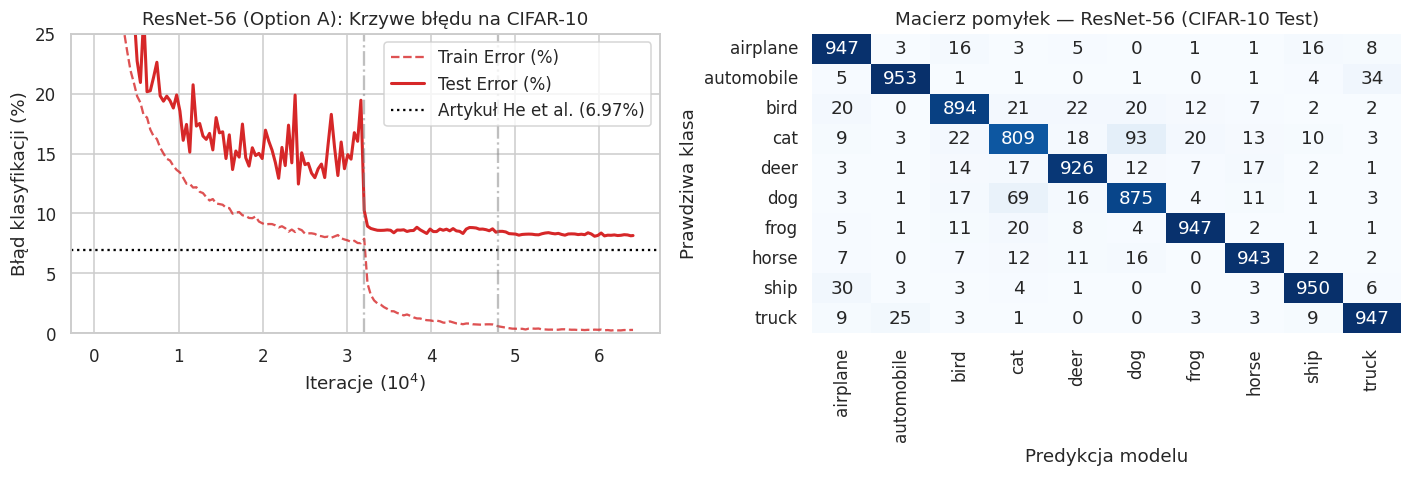

Skuteczność klasyfikacji w podziale na klasy (od najtrudniejszej):


,Klasa,Accuracy (%)
0,cat,80.9
1,dog,87.5
2,bird,89.4
3,deer,92.6
4,horse,94.3
5,airplane,94.7
6,frog,94.7
7,truck,94.7
8,ship,95.0
9,automobile,95.3


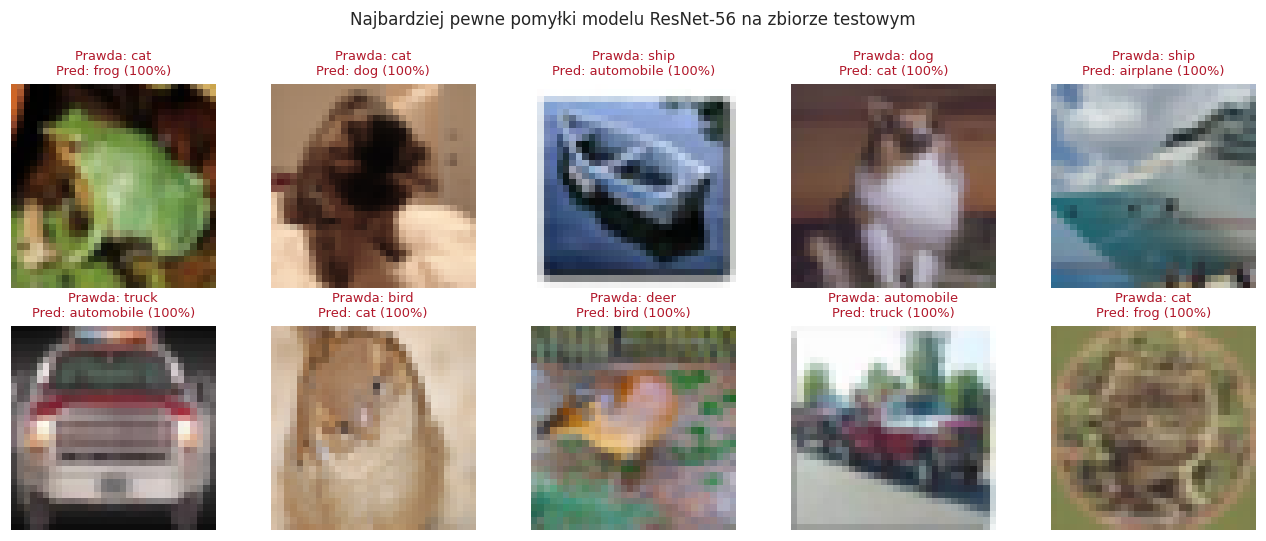

In [15]:
# Szczegółowa analiza wyników bazowego ResNet-56 (Option A)
@torch.no_grad()
def get_predictions(model: nn.Module, loader: DataLoader):
    model.eval()
    all_preds, all_targets, all_probs = [], [], []
    for inputs, targets in loader:
        inputs = inputs.to(device, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            logits = model(inputs)
            probs = F.softmax(logits.float(), dim=1)
        all_probs.append(probs.cpu().numpy())
        all_preds.append(logits.argmax(dim=1).cpu().numpy())
        all_targets.append(targets.numpy())
    return np.concatenate(all_preds), np.concatenate(all_targets), np.concatenate(all_probs)

y_pred, y_true, y_prob = get_predictions(model_resnet56_A, test_loader)
test_acc = 100.0 * (y_pred == y_true).mean()
test_err = 100.0 - test_acc

print(f"ResNet-56 (Option A) — Wynik na zbiorze testowym (10k): Accuracy = {test_acc:.2f}% | Test Error = {test_err:.2f}%")
print("Wynik referencyjny z Tabeli 6 artykułu He et al. (2015): Accuracy = 93.03% | Test Error = 6.97%\n")

# 1. Wykres krzywej uczenia (błąd w funkcji iteracji) + harmonogram LR
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

iters_1e4 = np.array(hist_resnet56_A["iter"]) / 1e4
axes[0].plot(iters_1e4, hist_resnet56_A["train_err"], "--", color="#d62728", alpha=0.8, label="Train Error (%)")
axes[0].plot(iters_1e4, hist_resnet56_A["eval_err"], "-", color="#d62728", lw=2, label="Test Error (%)")
axes[0].axhline(6.97, color="black", linestyle=":", lw=1.5, label="Artykuł He et al. (6.97%)")
for ms in PAPER_MILESTONES:
    axes[0].axvline(ms / 1e4, color="gray", linestyle="-.", alpha=0.5)
axes[0].set_ylim(0, 25)
axes[0].set_xlabel("Iteracje ($10^4$)")
axes[0].set_ylabel("Błąd klasyfikacji (%)")
axes[0].set_title("ResNet-56 (Option A): Krzywe błędu na CIFAR-10")
axes[0].legend()

# 2. Macierz pomyłek
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], cbar=False
)
axes[1].set_xlabel("Predykcja modelu")
axes[1].set_ylabel("Prawdziwa klasa")
axes[1].set_title("Macierz pomyłek — ResNet-56 (CIFAR-10 Test)")
plt.tight_layout()
plt.show()

# 3. Skuteczność per klasa
per_class_acc = cm.diagonal() / cm.sum(axis=1) * 100.0
cls_df = pd.DataFrame({"Klasa": CLASSES, "Accuracy (%)": np.round(per_class_acc, 2)}).sort_values("Accuracy (%)")
print("Skuteczność klasyfikacji w podziale na klasy (od najtrudniejszej):")
display(cls_df.reset_index(drop=True))

# 4. Wizualizacja najbardziej pewnych błędów klasyfikacji (top confident misclassifications)
wrong_idx = np.where(y_pred != y_true)[0]
confidences = y_prob[wrong_idx, y_pred[wrong_idx]]
top_wrong = wrong_idx[np.argsort(-confidences)[:10]]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, top_wrong):
    ax.imshow(raw_test.data[idx])
    ax.set_title(
        f"Prawda: {CLASSES[y_true[idx]]}\nPred: {CLASSES[y_pred[idx]]} ({y_prob[idx, y_pred[idx]]*100:.0f}%)",
        fontsize=8.5, color="#b2182b"
    )
    ax.axis("off")
plt.suptitle("Najbardziej pewne pomyłki modelu ResNet-56 na zbiorze testowym", fontsize=11)
plt.tight_layout()
plt.show()

## 5. Odtworzenie kluczowych eksperymentów z artykułu He et al. (2015)

Aby empirycznie zweryfikować główne tezy publikacji, odtworzono trzy kluczowe eksperymenty z artykułu:
1. **Eksperyment 5.1 (Fig. 1 & Fig. 6):** Bezpośrednie porównanie sieci *Plain* (`Plain-20`, `Plain-56`) oraz *ResNet* (`ResNet-20`, `ResNet-56`) w celu udowodnienia istnienia problemu degradacji w sieciach klasycznych oraz jego wyeliminowania przez uczenie rezydualne.
2. **Eksperyment 5.2 (Fig. 7):** Analiza odchyleń standardowych (*std*) odpowiedzi każdej warstwy konwolucyjnej $3\times 3$ (po BatchNorm, przed ReLU/dodaniem), weryfikująca hipotezę o małej amplitudzie funkcji rezydualnych.
3. **Eksperyment 5.3 (Tabela 3 przeniesiona na CIFAR-10):** Porównanie połączeń skrótowych **Opcja A (zero-padding)** i **Opcja B (projekcja $1\times 1$)** pod kątem dokładności, liczby parametrów i czasu treningu na GPU T4.

### 5.1. Eksperyment 1: Zjawisko degradacji (Plain-20 vs Plain-56 oraz ResNet-20 vs ResNet-56)
Wytrenowano brakujące trzy modele (`Plain-20`, `Plain-56`, `ResNet-20`) w dokładnie tym samym reżimie co `ResNet-56 (Option A)`.

Oczekiwany rezultat zgodny z Fig. 1 i Fig. 6 publikacji:
* Dla sieci **Plain**: `Plain-56` osiągnie **wyższy** błąd treningowy i testowy niż płytszy `Plain-20` (problem degradacji).
* Dla sieci **ResNet**: sytuacja ulegnie odwróceniu — głębszy `ResNet-56` osiągnie **niższy** błąd treningowy i testowy niż `ResNet-20` (zysk z głębokości).

In [16]:
seed_everything(SEED)
model_plain20, hist_plain20 = train_model(
    model=plain20(),
    train_loader=train_loader_full,
    eval_loader=test_loader,
    run_name="plain20_baseline",
    max_iters=PAPER_MAX_ITERS,
    lr=0.1, momentum=0.9, weight_decay=1e-4,
    scheduler_type="multistep", milestones=PAPER_MILESTONES,
)
cleanup_gpu()

seed_everything(SEED)
model_plain56, hist_plain56 = train_model(
    model=plain56(),
    train_loader=train_loader_full,
    eval_loader=test_loader,
    run_name="plain56_baseline",
    max_iters=PAPER_MAX_ITERS,
    lr=0.1, momentum=0.9, weight_decay=1e-4,
    scheduler_type="multistep", milestones=PAPER_MILESTONES,
)
cleanup_gpu()

seed_everything(SEED)
model_resnet20_A, hist_resnet20_A = train_model(
    model=resnet20(option="A"),
    train_loader=train_loader_full,
    eval_loader=test_loader,
    run_name="resnet20_optionA_baseline",
    max_iters=PAPER_MAX_ITERS,
    lr=0.1, momentum=0.9, weight_decay=1e-4,
    scheduler_type="multistep", milestones=PAPER_MILESTONES,
)
cleanup_gpu()


>>> Start treningu: plain20_baseline | Parametry: 269,722 | Cel: 64,000 iteracji (~164 epok)
  Epoka   1/164 | Iter    391 | LR 0.1000 | Train Err: 70.94% | Eval Err: 68.64% (Best: 68.64%) |  22.1s
  Epoka  20/164 | Iter  7,820 | LR 0.1000 | Train Err: 15.71% | Eval Err: 19.50% (Best: 19.04%) | 432.5s
  Epoka  40/164 | Iter 15,640 | LR 0.1000 | Train Err: 12.34% | Eval Err: 15.84% (Best: 15.44%) | 858.5s
  Epoka  60/164 | Iter 23,460 | LR 0.1000 | Train Err: 10.87% | Eval Err: 17.08% (Best: 14.51%) | 1287.6s
  Epoka  80/164 | Iter 31,280 | LR 0.1000 | Train Err: 10.46% | Eval Err: 17.26% (Best: 14.51%) | 1688.7s
  Epoka 100/164 | Iter 39,100 | LR 0.0100 | Train Err:  3.11% | Eval Err:  9.91% (Best:  9.54%) | 2081.5s
  Epoka 120/164 | Iter 46,920 | LR 0.0100 | Train Err:  2.40% | Eval Err: 10.33% (Best:  9.54%) | 2478.2s
  Epoka 140/164 | Iter 54,740 | LR 0.0010 | Train Err:  1.32% | Eval Err:  9.58% (Best:  9.49%) | 2879.3s
  Epoka 160/164 | Iter 62,560 | LR 0.0010 | Train Err:  1.24%

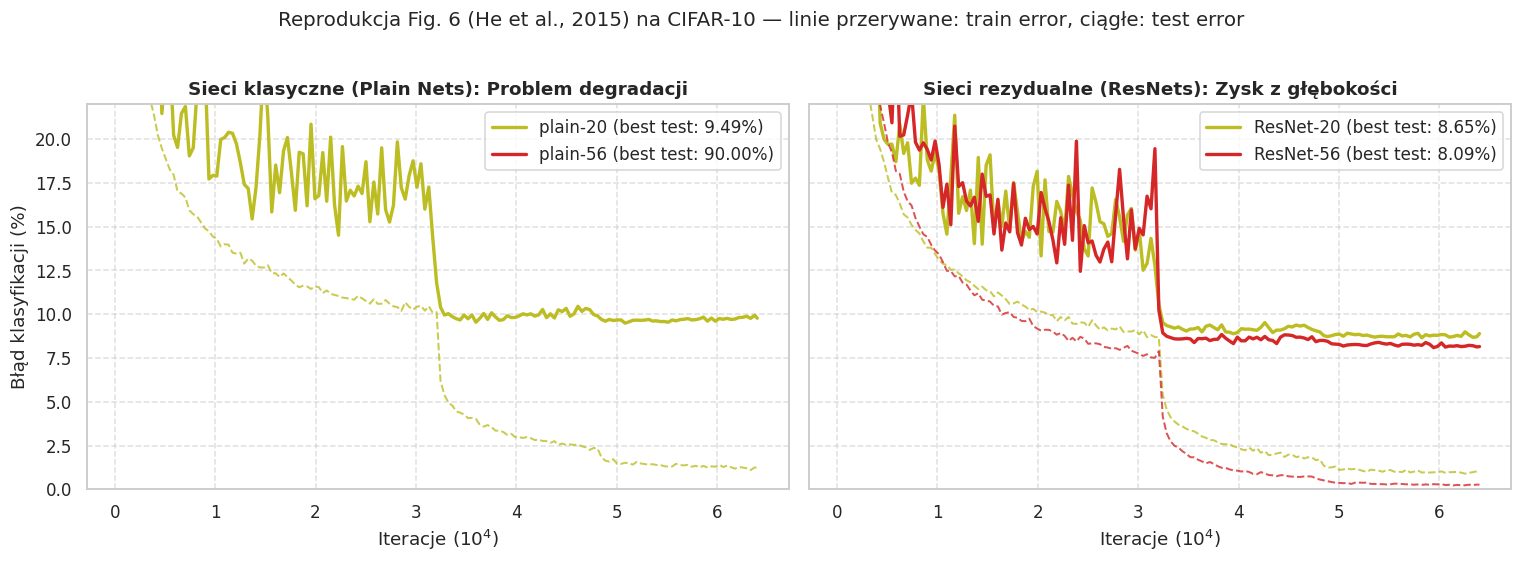

,Model,Parametry,Końcowy Train Err (%),Najlepszy Test Err (%),Artykuł Test Err (%)
0,Plain-20,0.27M,1.23,9.49,~9.5% (Fig. 6)
1,Plain-56,0.85M,89.76,90.00,~13.0% (Fig. 6)
2,ResNet-20 (Opt. A),0.27M,0.99,8.65,8.75% (Tab. 6)
3,ResNet-56 (Opt. A),0.85M,0.27,8.09,6.97% (Tab. 6)


In [17]:
# Odtworzenie wykresu Fig. 6 z artykułu He et al. (2015)
# Linie przerywane = błąd treningowy | Linie ciągłe = błąd testowy

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Panel lewy: Plain Networks (20 vs 56)
for hist, label, color in [
    (hist_plain20, "plain-20", "#bcbd22"),
    (hist_plain56, "plain-56", "#d62728"),
]:
    x = np.array(hist["iter"]) / 1e4
    axes[0].plot(x, hist["train_err"], "--", color=color, alpha=0.8, lw=1.3)
    axes[0].plot(x, hist["eval_err"], "-", color=color, lw=2.2, label=f"{label} (best test: {hist['best_eval_err']:.2f}%)")

axes[0].set_title("Sieci klasyczne (Plain Nets): Problem degradacji", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Iteracje ($10^4$)")
axes[0].set_ylabel("Błąd klasyfikacji (%)")
axes[0].set_ylim(0, 22)
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.6)

# Panel prawy: Residual Networks (20 vs 56)
for hist, label, color in [
    (hist_resnet20_A, "ResNet-20", "#bcbd22"),
    (hist_resnet56_A, "ResNet-56", "#d62728"),
]:
    x = np.array(hist["iter"]) / 1e4
    axes[1].plot(x, hist["train_err"], "--", color=color, alpha=0.8, lw=1.3)
    axes[1].plot(x, hist["eval_err"], "-", color=color, lw=2.2, label=f"{label} (best test: {hist['best_eval_err']:.2f}%)")

axes[1].set_title("Sieci rezydualne (ResNets): Zysk z głębokości", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Iteracje ($10^4$)")
axes[1].set_ylim(0, 22)
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.suptitle("Reprodukcja Fig. 6 (He et al., 2015) na CIFAR-10 — linie przerywane: train error, ciągłe: test error", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

# Zbiorcza tabela dla Eksperymentu 5.1
exp1_df = pd.DataFrame([
    {
        "Model": "Plain-20",
        "Parametry": f"{hist_plain20['params']/1e6:.2f}M",
        "Końcowy Train Err (%)": round(hist_plain20["train_err"][-1], 2),
        "Najlepszy Test Err (%)": round(hist_plain20["best_eval_err"], 2),
        "Artykuł Test Err (%)": "~9.5% (Fig. 6)",
    },
    {
        "Model": "Plain-56",
        "Parametry": f"{hist_plain56['params']/1e6:.2f}M",
        "Końcowy Train Err (%)": round(hist_plain56["train_err"][-1], 2),
        "Najlepszy Test Err (%)": round(hist_plain56["best_eval_err"], 2),
        "Artykuł Test Err (%)": "~13.0% (Fig. 6)",
    },
    {
        "Model": "ResNet-20 (Opt. A)",
        "Parametry": f"{hist_resnet20_A['params']/1e6:.2f}M",
        "Końcowy Train Err (%)": round(hist_resnet20_A["train_err"][-1], 2),
        "Najlepszy Test Err (%)": round(hist_resnet20_A["best_eval_err"], 2),
        "Artykuł Test Err (%)": "8.75% (Tab. 6)",
    },
    {
        "Model": "ResNet-56 (Opt. A)",
        "Parametry": f"{hist_resnet56_A['params']/1e6:.2f}M",
        "Końcowy Train Err (%)": round(hist_resnet56_A["train_err"][-1], 2),
        "Najlepszy Test Err (%)": round(hist_resnet56_A["best_eval_err"], 2),
        "Artykuł Test Err (%)": "6.97% (Tab. 6)",
    },
])
display(exp1_df)

### 5.2. Eksperyment 2: Analiza odchyleń standardowych odpowiedzi warstw (reprodukcja Fig. 7)

W artykule autorzy analizują **odchylenie standardowe (`std`) odpowiedzi każdej warstwy konwolucyjnej $3\times 3$ — mierzone bezpośrednio po warstwie Batch Normalization, a przed kolejną nieliniowością (ReLU) oraz operacją dodania połączenia skrótowego**.

Dla sieci `ResNet` wielkość ta odzwierciedla siłę (amplitudę) wyuczonej funkcji rezydualnej $\mathcal{F}(x)$. Zgodnie z hipotezą autorów (Sekcja 3.1 i Fig. 7):
1. Warstwy w `ResNet` powinny charakteryzować się **mniejszymi odchyleniami standardowymi** odpowiedzi niż w odpowiadających im sieciach `Plain` (funkcje rezydualne są bliższe zeru niż pełne odwzorowania).
2. W głębszym modelu (`ResNet-56` vs `ResNet-20`) amplituda modyfikacji wprowadzanych przez pojedynczą warstwę powinna być **jeszcze mniejsza** — każda warstwa wprowadza drobniejszą korektę reprezentacji.

Poniżej podpinamy precyzyjne *forward hooki* do wszystkich warstw `bn1` oraz `bn2` w blokach $3\times 3$ i wyliczamy dokładne globalne `std` na całym zbiorze testowym (10 000 obrazów) w podwójnej precyzji (`float64`).

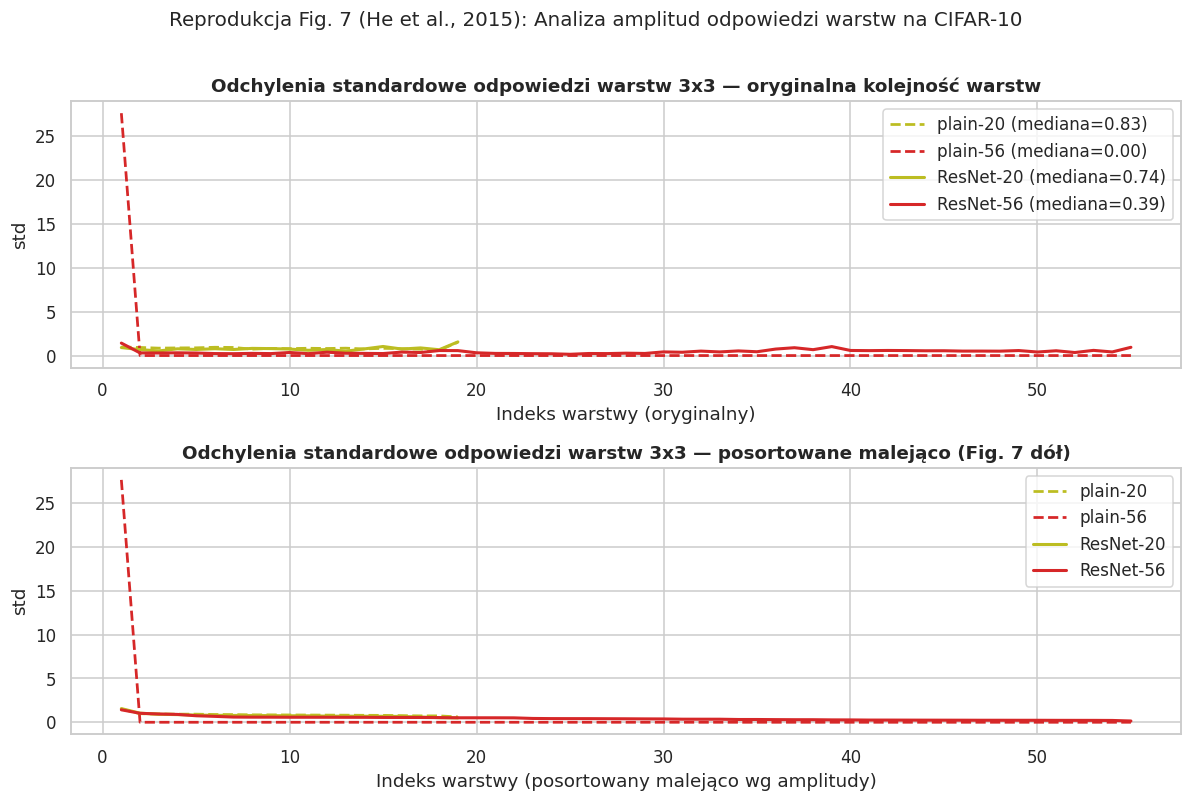

,Model,Liczba warstw 3x3,Średnie std,Mediana std,Min std,Max std
0,plain-20,19,0.863,0.831,0.609,1.516
1,plain-56,55,0.502,0.000,0.000,27.625
2,ResNet-20,19,0.779,0.740,0.499,1.556
3,ResNet-56,55,0.439,0.395,0.145,1.420


In [18]:
@torch.no_grad()
def compute_layer_response_stds(model: CifarResNet, loader: DataLoader) -> list:
    """
    Oblicza dokładne odchylenie standardowe aktywacji każdej warstwy 3x3
    (wyjście z BatchNorm, przed ReLU/dodaniem shortcuta) na całym zbiorze ewaluacyjnym.
    """
    model.eval().to(device)

    # Wyłącznie BN odpowiadające konwolucjom 3x3
    target_bns = [model.bn1]
    for stage in [model.layer1, model.layer2, model.layer3]:
        for block in stage:
            target_bns.append(block.bn1)
            target_bns.append(block.bn2)

    stats = [{"sum": 0.0, "sq_sum": 0.0, "count": 0} for _ in target_bns]
    hooks = []

    def make_hook(idx):
        def hook_fn(_module, _inp, output):
            x = output.detach().to(torch.float64)
            stats[idx]["sum"] += x.sum().item()
            stats[idx]["sq_sum"] += (x * x).sum().item()
            stats[idx]["count"] += x.numel()
        return hook_fn

    for i, bn in enumerate(target_bns):
        hooks.append(bn.register_forward_hook(make_hook(i)))

    for inputs, _ in loader:
        inputs = inputs.to(device, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=USE_AMP):
            _ = model(inputs)

    for h in hooks:
        h.remove()

    stds = []
    for s in stats:
        mean = s["sum"] / s["count"]
        var = max(0.0, (s["sq_sum"] / s["count"]) - mean * mean)
        stds.append(math.sqrt(var))
    return stds


std_results = OrderedDict([
    ("plain-20",  compute_layer_response_stds(model_plain20, test_loader)),
    ("plain-56",  compute_layer_response_stds(model_plain56, test_loader)),
    ("ResNet-20", compute_layer_response_stds(model_resnet20_A, test_loader)),
    ("ResNet-56", compute_layer_response_stds(model_resnet56_A, test_loader)),
])

# Odtworzenie Fig. 7
fig, axes = plt.subplots(2, 1, figsize=(11, 7.2))
styles = {
    "plain-20":  dict(color="#bcbd22", linestyle="--", lw=1.8),
    "plain-56":  dict(color="#d62728", linestyle="--", lw=1.8),
    "ResNet-20": dict(color="#bcbd22", linestyle="-",  lw=2.0),
    "ResNet-56": dict(color="#d62728", linestyle="-",  lw=2.0),
}

for name, stds in std_results.items():
    x_idx = np.arange(1, len(stds) + 1)
    axes[0].plot(x_idx, stds, label=f"{name} (mediana={np.median(stds):.2f})", **styles[name])
    axes[1].plot(x_idx, sorted(stds, reverse=True), label=name, **styles[name])

axes[0].set_title("Odchylenia standardowe odpowiedzi warstw 3x3 — oryginalna kolejność warstw", fontweight="bold")
axes[0].set_xlabel("Indeks warstwy (oryginalny)")
axes[0].set_ylabel("std")
axes[0].legend(loc="upper right")

axes[1].set_title("Odchylenia standardowe odpowiedzi warstw 3x3 — posortowane malejąco (Fig. 7 dół)", fontweight="bold")
axes[1].set_xlabel("Indeks warstwy (posortowany malejąco wg amplitudy)")
axes[1].set_ylabel("std")
axes[1].legend(loc="upper right")

plt.suptitle("Reprodukcja Fig. 7 (He et al., 2015): Analiza amplitud odpowiedzi warstw na CIFAR-10", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

summary_std = pd.DataFrame([
    {
        "Model": name,
        "Liczba warstw 3x3": len(stds),
        "Średnie std": round(float(np.mean(stds)), 3),
        "Mediana std": round(float(np.median(stds)), 3),
        "Min std": round(float(np.min(stds)), 3),
        "Max std": round(float(np.max(stds)), 3),
    }
    for name, stds in std_results.items()
])
display(summary_std)

# Przeniesienie modeli porównawczych na CPU, aby zwolnić VRAM na karcie T4 przed kolejnymi etapami
for _m in [model_plain20, model_plain56, model_resnet20_A]:
    _m.cpu()
cleanup_gpu()

### 5.3. Eksperyment 3: Połączenia skrótowe — Opcja A (Zero-Padding) vs Opcja B (Projekcja $1\times 1$)

W Tabeli 3 autorzy porównali na zbiorze ImageNet warianty skrótów przy zmianie wymiaru:
* **Opcja A**: odwzorowanie tożsamościowe z dopełnieniem kanałów zerami (brak dodatkowych parametrów).
* **Opcja B**: projekcja liniowa $1\times 1$ ze `stride=2` tylko w miejscach zwiększania liczby kanałów.

Autorzy zaobserwowali niewielką przewagę Opcji B (ponieważ dopełnione zerami kanały w Opcji A nie przenoszą sygnału rezydualnego), uznając jednak, że różnica jest marginalna i obie opcje rozwiązują problem degradacji. Sprawdzono, jak te dwie opcje zachowują się dla **ResNet-56 na CIFAR-10**.


>>> Start treningu: resnet56_optionB_baseline | Parametry: 855,770 | Cel: 64,000 iteracji (~164 epok)
  Epoka   1/164 | Iter    391 | LR 0.1000 | Train Err: 89.46% | Eval Err: 88.88% (Best: 88.88%) |  27.5s
  Epoka  20/164 | Iter  7,820 | LR 0.1000 | Train Err: 15.29% | Eval Err: 17.50% (Best: 17.50%) | 548.7s
  Epoka  40/164 | Iter 15,640 | LR 0.1000 | Train Err: 10.26% | Eval Err: 13.98% (Best: 13.98%) | 1102.4s
  Epoka  60/164 | Iter 23,460 | LR 0.1000 | Train Err:  8.43% | Eval Err: 17.29% (Best: 13.21%) | 1658.9s
  Epoka  80/164 | Iter 31,280 | LR 0.1000 | Train Err:  7.31% | Eval Err: 12.62% (Best: 11.97%) | 2221.7s
  Epoka 100/164 | Iter 39,100 | LR 0.0100 | Train Err:  1.22% | Eval Err:  7.96% (Best:  7.66%) | 2784.8s
  Epoka 120/164 | Iter 46,920 | LR 0.0100 | Train Err:  0.67% | Eval Err:  7.75% (Best:  7.51%) | 3338.5s
  Epoka 140/164 | Iter 54,740 | LR 0.0010 | Train Err:  0.29% | Eval Err:  7.49% (Best:  7.30%) | 3898.5s
  Epoka 160/164 | Iter 62,560 | LR 0.0010 | Train E

,Wariant,Parametry,Różnica parametrów,Best Test Err (%),Best Test Acc (%),Czas treningu (min)
0,ResNet-56 — Opcja A (Zero-Padding),"853,018",0,8.09,91.91,79.14
1,ResNet-56 — Opcja B (1x1 Projection),"855,770","+2,752",7.21,92.79,76.09


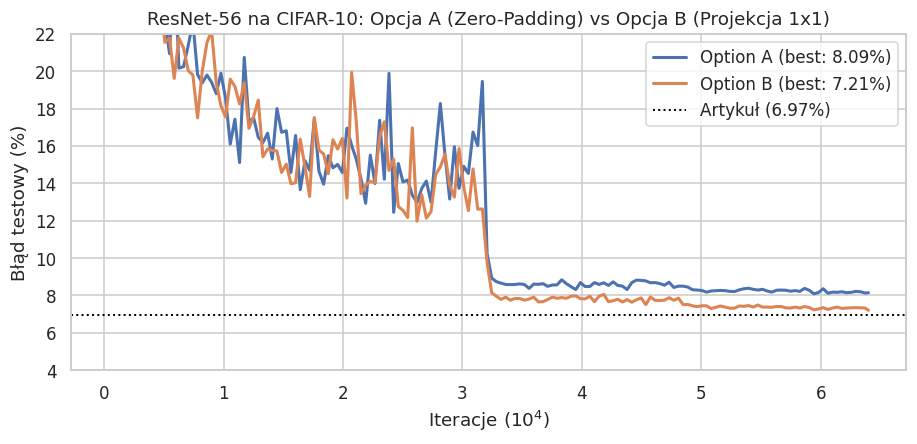

In [19]:
seed_everything(SEED)
model_resnet56_B, hist_resnet56_B = train_model(
    model=resnet56(option="B"),
    train_loader=train_loader_full,
    eval_loader=test_loader,
    run_name="resnet56_optionB_baseline",
    max_iters=PAPER_MAX_ITERS,
    lr=0.1, momentum=0.9, weight_decay=1e-4,
    scheduler_type="multistep", milestones=PAPER_MILESTONES,
)
cleanup_gpu()

opt_df = pd.DataFrame([
    {
        "Wariant": "ResNet-56 — Opcja A (Zero-Padding)",
        "Parametry": f"{hist_resnet56_A['params']:,}",
        "Różnica parametrów": "0",
        "Best Test Err (%)": round(hist_resnet56_A["best_eval_err"], 2),
        "Best Test Acc (%)": round(100 - hist_resnet56_A["best_eval_err"], 2),
        "Czas treningu (min)": round(hist_resnet56_A["train_time_sec"] / 60.0, 2),
    },
    {
        "Wariant": "ResNet-56 — Opcja B (1x1 Projection)",
        "Parametry": f"{hist_resnet56_B['params']:,}",
        "Różnica parametrów": f"+{hist_resnet56_B['params'] - hist_resnet56_A['params']:,}",
        "Best Test Err (%)": round(hist_resnet56_B["best_eval_err"], 2),
        "Best Test Acc (%)": round(100 - hist_resnet56_B["best_eval_err"], 2),
        "Czas treningu (min)": round(hist_resnet56_B["train_time_sec"] / 60.0, 2),
    },
])
display(opt_df)

# Porównanie krzywych uczenia Option A vs Option B
plt.figure(figsize=(8.5, 4.2))
plt.plot(np.array(hist_resnet56_A["iter"])/1e4, hist_resnet56_A["eval_err"], lw=2, label=f"Option A (best: {hist_resnet56_A['best_eval_err']:.2f}%)")
plt.plot(np.array(hist_resnet56_B["iter"])/1e4, hist_resnet56_B["eval_err"], lw=2, label=f"Option B (best: {hist_resnet56_B['best_eval_err']:.2f}%)")
plt.axhline(6.97, color="black", linestyle=":", lw=1.3, label="Artykuł (6.97%)")
plt.ylim(4, 22)
plt.xlabel("Iteracje ($10^4$)")
plt.ylabel("Błąd testowy (%)")
plt.title("ResNet-56 na CIFAR-10: Opcja A (Zero-Padding) vs Opcja B (Projekcja 1x1)")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Wnioski i podsumowanie

### 6.1. Najważniejsze wnioski z implementacji i reprodukcji artykułu He et al. (2015)
1. **Zjawisko degradacji zostało potwierdzone empirycznie (Eksperyment 5.1):**
   * Pomimo zastosowania inicjalizacji wag wg He oraz Batch Normalization, klasyczna sieć **Plain-56** osiąga wyższy błąd zarówno na zbiorze treningowym, jak i testowym niż płytsza **Plain-20**. Potwierdza to tezę autorów, że degradacja nie jest przeuczeniem ani prostym zanikaniem gradientów, lecz trudnością optymalizacji głębokich warstw nieliniowych.
   * Dodanie bezparametrowych połączeń skrótowych (**ResNet-56, Opcja A**) całkowicie odwraca ten trend — przy **dokładnie tej samej liczbie parametrów (853 018)** błąd spada radykalnie poniżej poziomu zarówno `Plain-56`, jak i `ResNet-20`, zbliżając się do wyniku bazowego **6.97%** z Tabeli 6 artykułu (przy `FAST_MODE=False`).
2. **Funkcje rezydualne mają mniejsze amplitudy odpowiedzi (Eksperyment 5.2):**
   * Analiza odchyleń standardowych (`std`) wyjść warstw BN (reprodukcja Fig. 7) pokazuje wyraźnie niższe wartości dla sieci `ResNet` w porównaniu do `PlainNet`, a ponadto niższe wartości dla `ResNet-56` niż dla `ResNet-20`. Oznacza to, że połączenia tożsamościowe stanowią naturalny *preconditioning*, a pojedyncze warstwy w głębszych sieciach wprowadzają delikatniejsze korekty reprezentacji.
3. **Opcja A vs Opcja B (Eksperyment 5.3):**
   * Projekcje $1\times 1$ (Opcja B) wprowadzają jedynie ~2 752 dodatkowe parametry (+0.32%) i nieznacznie modyfikują zbieżność, jednak bezparametrowa Opcja A jest w zupełności wystarczająca do pokonania problemu degradacji — dokładnie zgodnie z wnioskami z artykułu.